# Machine Learning for Business

## Introduction

Bike-sharing is popular in cities. But the number of rentals changes every day because of weather, season and holidays. This makes planning difficult for companies.
This project uses the UCI Bike Sharing dataset (Fanaee-T and Gama, 2013). It has 731 days of data from Washington D.C. (2011–2012).
Objectives:
Group similar days with K-Means and Hierarchical clustering, and compare them.
Give simple advice to the company.

In [1]:
#So before doing any analysis we need to load the tools.
#Without these libraries we cannot read files, create charts or build models.
#This is always the first step in any data science project.
import pandas as pd #for reading and working with structured data.
import seaborn as sns #for creating clear, informative. 
import matplotlib.pyplot as plt #for charts and graphs.
import numpy as np #for numerical operations and data manipulation
import warnings 
warnings.filterwarnings('ignore')
import statsmodels
import xarray

In [2]:
df = pd.read_csv('day.csv')

In [3]:
df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [4]:
df.shape

(731, 16)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB


In [6]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


### Variable types
The dataset contains different types of variables:
- Categorical: season, yr, mnth, holiday, weekday, workingday, weathersit
- Continuous: temp, atemp, hum, windspeed
- Discrete (counts): casual, registered, cnt
- Date: dteday
- Identifier: instant (row number, not used in the analysis)

As we can see, the dataset has 16 columns with categorical, continuous and discrete
variables, which meets the requirement of at least 7 columns of different types.

Then i need to check if i have any missing values. Missing values are important because:

they can reduce model accuracy

they can affect statistical analysis

they must be cleaned before machine learning

In [9]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

I checked and i dont have any missing values

In [10]:
# i will check duplicates to ensure data consistency and reliability.
# Duplicate rows can skew analysis and model training by giving
# certain observations more weight than they deserve.
df.duplicated().sum()

np.int64(0)

I saw The result showed that the dataset contained no duplicate observations; therefore, no rows were removed.

In [11]:
# I converted the date column to date format because pandas reads it as text.
# This is needed to plot the data over time and for the SARIMA model later.
df['dteday'] = pd.to_datetime(df['dteday'])

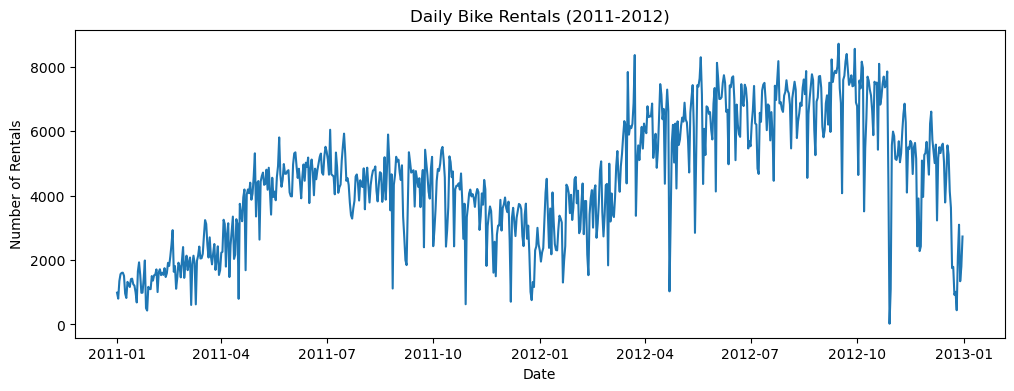

In [12]:
# I used a line plot to see the trend and seasonality of daily rentals.
fig, ax = plt.subplots(figsize = (12, 4))
ax.plot(df['dteday'], df['cnt'])
ax.set_title('Daily Bike Rentals (2011-2012)')
ax.set_xlabel('Date')
ax.set_ylabel('Number of Rentals')
plt.show()

From this plot i see , daily rentals increase from 2011 to 2012, which shows an upward trend. Rentals are higher in summer and lower in winter, which shows a yearly seasonality. There are also some days with very low rentals, probably because of bad weather or holidays.

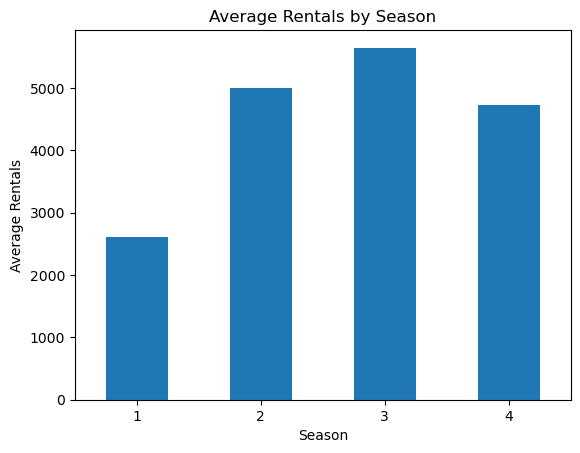

In [13]:
# I used a bar chart to compare the average rentals for each season
# (1 = spring, 2 = summer, 3 = fall, 4 = winter).
# This shows how the season affects demand and will help me describe the clusters later.
season_avg = df.groupby('season')['cnt'].mean()

fig, ax = plt.subplots()
season_avg.plot(kind = 'bar', ax = ax, rot = 0)
ax.set_title('Average Rentals by Season')
ax.set_xlabel('Season')
ax.set_ylabel('Average Rentals')
plt.show()

So from chart , I saw fall (season 3) has the highest average rentals with about 5,600 per day, followed by summer (about 5,000) and winter (about 4,700). Spring (season 1) has the lowest average with about 2,600 rentals per day. This shows that the season has a strong effect on bike demand, with more rentals in warmer months.

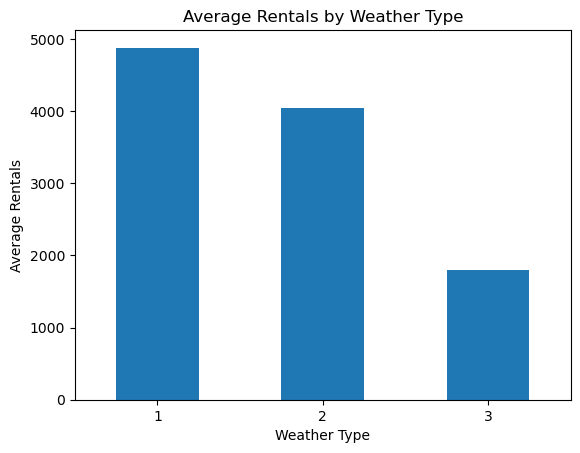

In [14]:
# I used a bar chart to compare the average rentals for each weather type
# (1 = clear, 2 = mist/cloudy, 3 = light rain/snow).
# This shows how bad weather reduces demand, which supports my business problem.
weather_avg = df.groupby('weathersit')['cnt'].mean()

fig, ax = plt.subplots()
weather_avg.plot(kind = 'bar', ax = ax, rot = 0)
ax.set_title('Average Rentals by Weather Type')
ax.set_xlabel('Weather Type')
ax.set_ylabel('Average Rentals')
plt.show()

so from this table i see, clear days (weather 1) have the highest average rentals with about 4,900 per day,followed by misty or cloudy days (about 4,000).On days with light rain or snow (weather 3), rentals drop to about 1,800,which is less than half of clear days.There are no days with heavy rain (weather 4) in the daily dataset.This shows that bad weather strongly reduces bike demand.

In [15]:
# I used a correlation table to see which variables are linked to rentals.
# This is important because if two variables are almost the same
# (like temp and atemp), I should keep only one for clustering,
# otherwise temperature would count twice.
cols = ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
print(df[cols].corr().round(2))

            temp  atemp   hum  windspeed  casual  registered   cnt
temp        1.00   0.99  0.13      -0.16    0.54        0.54  0.63
atemp       0.99   1.00  0.14      -0.18    0.54        0.54  0.63
hum         0.13   0.14  1.00      -0.25   -0.08       -0.09 -0.10
windspeed  -0.16  -0.18 -0.25       1.00   -0.17       -0.22 -0.23
casual      0.54   0.54 -0.08      -0.17    1.00        0.40  0.67
registered  0.54   0.54 -0.09      -0.22    0.40        1.00  0.95
cnt         0.63   0.63 -0.10      -0.23    0.67        0.95  1.00


i saw from this table, temp and atemp have a correlation of 0.99, which means they are almost the same variable. Therefore, I will keep only temp for clustering.Temperature has a strong positive correlation with rentals (0.63), which means more people rent bikes on warmer days. Windspeed has a weak negative correlation (-0.23),and humidity has almost no correlation (-0.10) with rentals.Casual and registered are highly correlated with cnt because cnt is the sum of casual and registered users, so they will not be used together in clustering.

### Clustering

I chose K-Means and Agglomerative (Hierarchical) clustering for two reasons. K-Means is simple, fast and works well with numeric data like temperature and rentals. Agglomerative clustering works in a different way: it joins similar days step by step, and the dendrogram helps to choose the number of clusters. Using two different methods lets me compare the results and choose the best one.

###### Data preparation for clustering

In [16]:
# I selected 4 numeric columns to group similar days:
# temp (temperature), hum (humidity), windspeed and cnt (total rentals).
# I kept only temp and not atemp because they are almost the same (correlation 0.99).
# I did not use casual and registered because cnt is already their sum.
# I did not use the categorical columns (season, weathersit...) because K-Means
# and Hierarchical clustering use distances, which work best with numeric values.
features = df[['temp', 'hum', 'windspeed', 'cnt']]

In [17]:
# Load the values of the 4 columns
x = features.values

# Show the first 5 rows
print(features.head())

       temp       hum  windspeed   cnt
0  0.344167  0.805833   0.160446   985
1  0.363478  0.696087   0.248539   801
2  0.196364  0.437273   0.248309  1349
3  0.200000  0.590435   0.160296  1562
4  0.226957  0.436957   0.186900  1600


In [18]:
# I used StandardScaler to put all the columns on the same scale.
# This is important because cnt has big values while temp, hum and windspeed
# are between 0 and 1. Without scaling, cnt would control the clustering.
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x = scaler.fit_transform(x)

# Show the first 5 rows after scaling
print(x[:5])

[[-0.82666213  1.25017133 -0.38789169 -1.81795256]
 [-0.72109471  0.47911298  0.74960172 -1.91299949]
 [-1.63465665 -1.33927398  0.74663186 -1.62992496]
 [-1.61477973 -0.26318156 -0.38982855 -1.51989782]
 [-1.46741392 -1.34149414 -0.04630665 -1.50026856]]


i saw, after scaling all the columns have values around 0. Positive values mean above average and negative values mean below average.For example, the first days of January 2011 have negative values for temp and cnt,which means they were colder and had fewer rentals than an average day.Now all 4 variables have the same importance in the clustering.

### K-Means Clustering

In [19]:
# I used the Elbow Method to find the best number of clusters for K-Means.
# When SSE stops decreasing a lot, this point (the "elbow") shows the best number of clusters.
from sklearn.cluster import KMeans
sse = []   # Declare an array for the storage of values for Sum of Squares (SSE) Errors

# Set the loop from the minimum and maximum values
for i in range(1, 11):
    kmeans = KMeans(n_clusters = i, max_iter = 300, n_init = 10, random_state = 38)
    kmeans.fit(x)                    # Training the model by calling fit() method
    sse.append(kmeans.inertia_)      # Store kmeans.inertia_ in the array sse

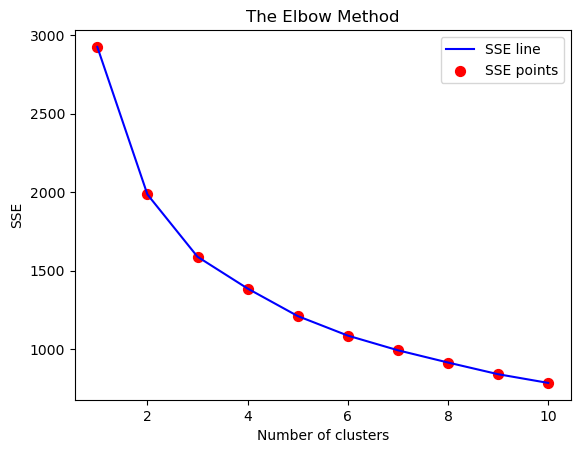

In [20]:
# Plotting the results onto a line graph with points in a different color
plt.plot(range(1, 11), sse, linestyle = '-', color = 'blue', label = 'SSE line')
plt.scatter(range(1, 11), sse, color = 'red', marker = 'o', s = 50, label = 'SSE points')

plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('SSE')  # sum of squares errors
plt.legend()
plt.show()

so i can see, the SSE decreases quickly from 1 to 3 clusters and then decreases more slowly. The elbow appears around k = 3, but it is not very clear. Therefore, I will also use the Silhouette Score and the Davies-Bouldin Index to confirm the best number of clusters.

In [21]:
# I used the Silhouette Score and the Davies-Bouldin Index to confirm the best number of clusters.
# Silhouette Score: higher is better (clusters are well separated).
# Davies-Bouldin Index: lower is better (clusters are compact and far from each other).
from sklearn.metrics import davies_bouldin_score, silhouette_score

# Function to perform k-means clustering and calculate metrics
def perform_clustering(n_clusters, data):
    kmeans = KMeans(n_clusters = n_clusters, random_state = 42)
    labels = kmeans.fit_predict(data)
    db_index = davies_bouldin_score(data, labels)
    silhouette_avg = silhouette_score(data, labels)
    return db_index, silhouette_avg

# Vary the number of clusters and store metrics
cluster_range = range(2, 11)
db_scores = []
silhouette_scores = []

for n_clusters in cluster_range:
    db_index, silhouette_avg = perform_clustering(n_clusters, x)
    db_scores.append(db_index)
    silhouette_scores.append(silhouette_avg)

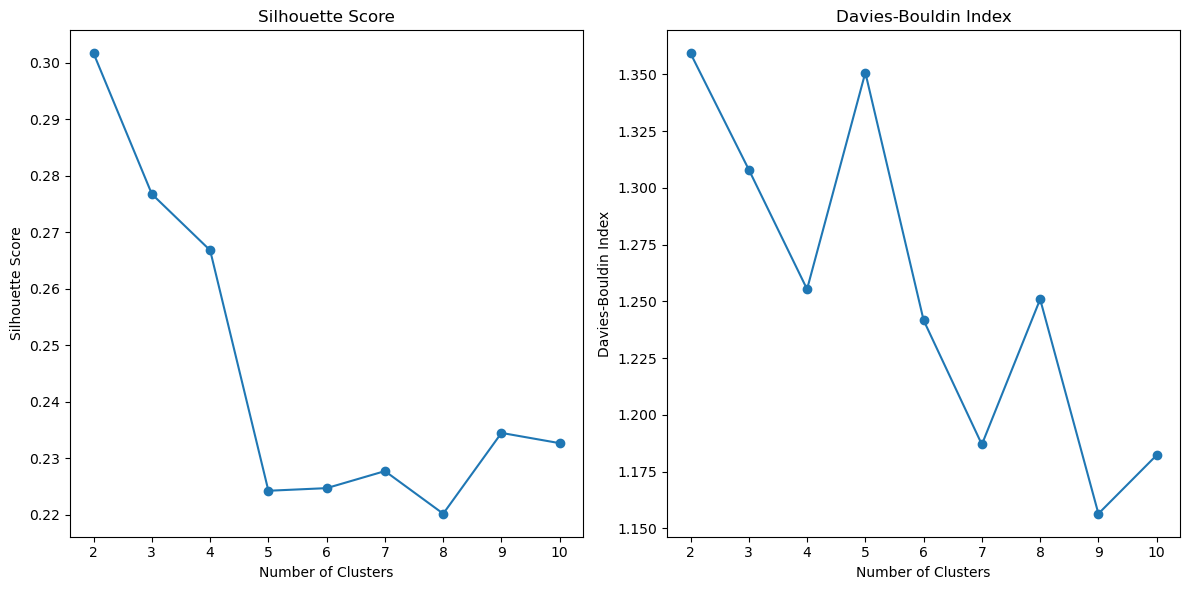

In [22]:
# Plot the Silhouette Score and the Davies-Bouldin Index
plt.figure(figsize = (12, 6))

plt.subplot(1, 2, 1)
plt.plot(cluster_range, silhouette_scores, marker = 'o')
plt.title('Silhouette Score')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')

plt.subplot(1, 2, 2)
plt.plot(cluster_range, db_scores, marker = 'o')
plt.title('Davies-Bouldin Index')
plt.xlabel('Number of Clusters')
plt.ylabel('Davies-Bouldin Index')

plt.tight_layout()
plt.show()

In [23]:
# I used argmax and argmin to find the best number of clusters automatically.
# Silhouette: the highest value is the best. Davies-Bouldin: the lowest value is the best.
optimal_clusters_silhouette = np.argmax(silhouette_scores) + 2  # +2 because the range starts from 2
optimal_clusters_db = np.argmin(db_scores) + 2  # +2 because the range starts from 2

print(f'Optimal Clusters (Silhouette): {optimal_clusters_silhouette}')
print(f'Optimal Clusters (Davies-Bouldin): {optimal_clusters_db}')

Optimal Clusters (Silhouette): 2
Optimal Clusters (Davies-Bouldin): 9


i saw , the Silhouette Score is highest at k = 2 (about 0.30) and decreases after k = 4, with a big drop at k = 5. The Davies-Bouldin Index is lowest at k = 9 (about 1.15), but it also has a local minimum at k = 4 (about 1.25). The two metrics do not agree. k = 2 is too simple for business use, and k = 9 has a low Silhouette Score and too many groups to interpret. Therefore, I chose k = 4 as a balance between the two metrics and the Elbow Method. The Silhouette values around 0.3 show that the clusters are only moderately separated.

In [24]:
# I trained K-Means with 4 clusters, based on the Elbow Method,
# the Silhouette Score and the Davies-Bouldin Index.
kmeans = KMeans(n_clusters = 4, max_iter = 300, n_init = 10, random_state = 38)
y_kmeans = kmeans.fit_predict(x)

# I added the cluster number to the original data to understand each group
df['kmeans_cluster'] = y_kmeans

# Number of days in each cluster
print(df['kmeans_cluster'].value_counts())

kmeans_cluster
2    318
1    149
0    133
3    131
Name: count, dtype: int64


In [25]:
# I calculated the average of each variable for each cluster (on the original values, not scaled).
# This helps me describe each group of days in simple business words.
print(df.groupby('kmeans_cluster')[['temp', 'hum', 'windspeed', 'cnt']].mean().round(2))

                temp   hum  windspeed      cnt
kmeans_cluster                                
0               0.46  0.81       0.22  3103.22
1               0.30  0.61       0.14  3165.40
2               0.65  0.63       0.16  6041.14
3               0.37  0.47       0.29  3719.27


As we can see, K-Means created 4 groups of days:

Cluster 2 (318 days): warm days (0.65 × 41 = 26.7 about 27°C) with the highest rentals (about 6,041 per day).
Cluster 3 (131 days):0.37 × 41 = 15.2 ≈ 15°C cool, dry and windy days with medium rentals (about 3,719).
Cluster 1 (149 days): (0.30 × 41 = 12.3 cold days (about 12°C) with low rentals (about 3,165).
Cluster 0 (133 days):0.46 × 41 = 18.9 ≈ 19°C mild but very humid days with the lowest rentals (about 3,103).
For the business, this means the company should have the most bikes available on warm days, and can use humid or cold days for maintenance and bike repairs

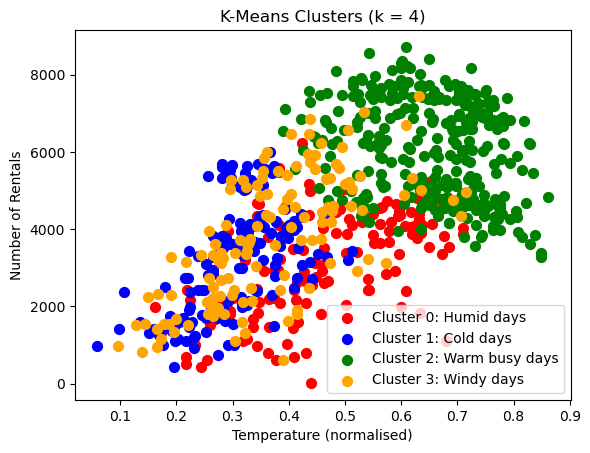

In [26]:
# I used a scatter plot to visualise the 4 K-Means clusters using temperature and rentals.
# I used the original values (not scaled) so the chart is easy to understand.
plt.scatter(df.loc[y_kmeans == 0, 'temp'], df.loc[y_kmeans == 0, 'cnt'], s = 50, c = 'red', label = 'Cluster 0: Humid days')
plt.scatter(df.loc[y_kmeans == 1, 'temp'], df.loc[y_kmeans == 1, 'cnt'], s = 50, c = 'blue', label = 'Cluster 1: Cold days')
plt.scatter(df.loc[y_kmeans == 2, 'temp'], df.loc[y_kmeans == 2, 'cnt'], s = 50, c = 'green', label = 'Cluster 2: Warm busy days')
plt.scatter(df.loc[y_kmeans == 3, 'temp'], df.loc[y_kmeans == 3, 'cnt'], s = 50, c = 'orange', label = 'Cluster 3: Windy days')

plt.title('K-Means Clusters (k = 4)')
plt.xlabel('Temperature (normalised)')
plt.ylabel('Number of Rentals')
plt.legend()
plt.show()

I saw from scatter plot , the warm busy days (cluster 2) are clearly separated from the other groups, with high temperatures and high rentals. The humid days (cluster 0) have mild temperatures but lower rentals. The cold days (cluster 1) and windy days (cluster 3) overlap in this chart because they are mainly different in windspeed and humidity, which are not shown here. This overlap also explains the moderate Silhouette Score of about 0.27.

### Hierarchical Clustering (Agglomerative

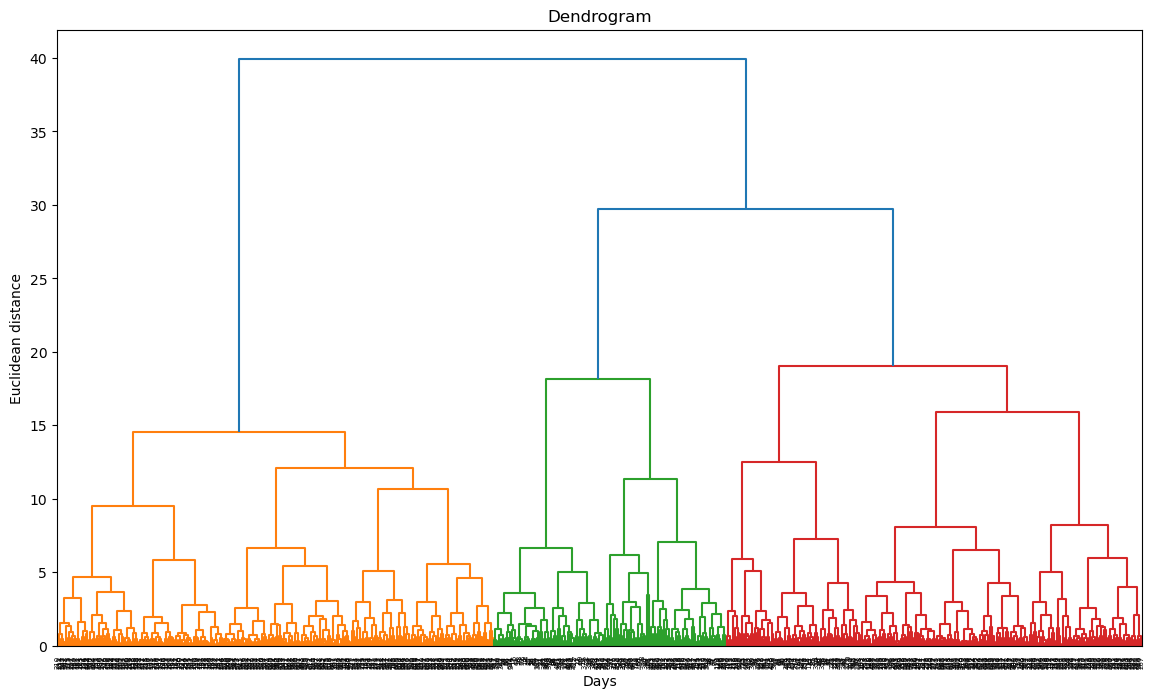

In [27]:
# I used a dendrogram to see how the days are grouped step by step.
# The dendrogram helps me choose the number of clusters: I look for the longest
# vertical lines, where cutting the tree gives well separated groups.
# I used the 'ward' method because it creates compact clusters, similar to K-Means,
# which makes the comparison between the two algorithms fair.
import scipy.cluster.hierarchy as sch

plt.figure(figsize = (14, 8))
dendrogrm = sch.dendrogram(sch.linkage(x, method = 'ward'))
plt.title('Dendrogram')
plt.xlabel('Days')
plt.ylabel('Euclidean distance')
plt.show()

As we can see, the biggest vertical distances in the dendrogram are between about 20 and 40. Cutting the tree between 20.5 and 30 gives 3 clusters (orange, green and red). Cutting above 30 gives 2 clusters. I will use the Silhouette Score and the Davies-Bouldin Index to confirm the best number of clusters.

In [28]:
# I used the Silhouette Score and the Davies-Bouldin Index to choose the best number
# of clusters for Agglomerative clustering, like I did for K-Means.
from sklearn.cluster import AgglomerativeClustering

# Function to perform hierarchical clustering and calculate metrics
def perform_hc(n_clusters, data):
    hc = AgglomerativeClustering(n_clusters = n_clusters, metric = 'euclidean', linkage = 'ward')
    labels = hc.fit_predict(data)
    db_index = davies_bouldin_score(data, labels)
    silhouette_avg = silhouette_score(data, labels)
    return db_index, silhouette_avg

# Vary the number of clusters and store metrics
hc_db_scores = []
hc_silhouette_scores = []

for n_clusters in cluster_range:
    db_index, silhouette_avg = perform_hc(n_clusters, x)
    hc_db_scores.append(db_index)
    hc_silhouette_scores.append(silhouette_avg)

# Print the exact values for each number of clusters
for k, s, d in zip(cluster_range, hc_silhouette_scores, hc_db_scores):
    print(f'k = {k}   Silhouette = {s:.3f}   Davies-Bouldin = {d:.3f}')

k = 2   Silhouette = 0.248   Davies-Bouldin = 1.438
k = 3   Silhouette = 0.238   Davies-Bouldin = 1.439
k = 4   Silhouette = 0.211   Davies-Bouldin = 1.494
k = 5   Silhouette = 0.212   Davies-Bouldin = 1.388
k = 6   Silhouette = 0.203   Davies-Bouldin = 1.255
k = 7   Silhouette = 0.187   Davies-Bouldin = 1.384
k = 8   Silhouette = 0.193   Davies-Bouldin = 1.345
k = 9   Silhouette = 0.192   Davies-Bouldin = 1.332
k = 10   Silhouette = 0.197   Davies-Bouldin = 1.333


i saw, the best Silhouette Score is at k = 2 (0.248), and k = 3 is almost the same (0.238). The best Davies-Bouldin Index is at k = 6 (1.255), but its Silhouette Score is low (0.203). I chose k = 3 because it matches the dendrogram and gives more useful groups than k = 2. Compared to K-Means, Agglomerative clustering has worse scores, so K-Means separated the days better.

In [29]:
# I trained Agglomerative clustering with 3 clusters, based on the dendrogram,
# the Silhouette Score and the Davies-Bouldin Index.
# import the library for Agglomerative clustering
from sklearn.cluster import AgglomerativeClustering

# Initialise an object 'hc' by calling a method 'AgglomerativeClustering'
hc = AgglomerativeClustering(n_clusters = 3, metric = 'euclidean', linkage = 'ward')

# Train the model by calling a method 'fit_predict(x)'
y_hc = hc.fit_predict(x)

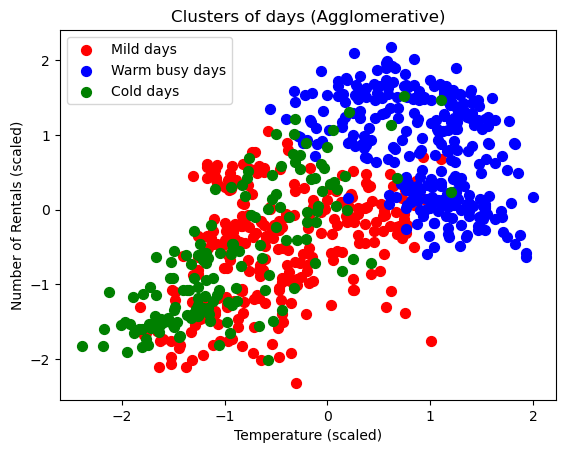

In [30]:
# I used a scatter plot to visualise the 3 clusters, using temperature (column 0)
# and number of rentals (column 3) from the scaled data.
# Visualising the clusters
plt.scatter(x[y_hc == 0, 0], x[y_hc == 0, 3], s = 50, c = 'red', label = 'Mild days')
plt.scatter(x[y_hc == 1, 0], x[y_hc == 1, 3], s = 50, c = 'blue', label = 'Warm busy days')
plt.scatter(x[y_hc == 2, 0], x[y_hc == 2, 3], s = 50, c = 'green', label = 'Cold days')
plt.title('Clusters of days (Agglomerative)')
plt.xlabel('Temperature (scaled)')
plt.ylabel('Number of Rentals (scaled)')
plt.legend()
plt.show()

## Comparison of K-Means and Agglomerative Clustering

In [31]:
# I calculated the Silhouette Score and the Davies-Bouldin Index for my two final models
# (K-Means with 4 clusters and Agglomerative with 3 clusters) to compare them directly.
kmeans_silhouette = silhouette_score(x, y_kmeans)
kmeans_db = davies_bouldin_score(x, y_kmeans)

hc_silhouette = silhouette_score(x, y_hc)
hc_db = davies_bouldin_score(x, y_hc)

# I put the results in a table to make the comparison easy to read.
comparison = pd.DataFrame({
    'Algorithm': ['K-Means', 'Agglomerative'],
    'Number of clusters': [4, 3],
    'Silhouette Score': [round(kmeans_silhouette, 3), round(hc_silhouette, 3)],
    'Davies-Bouldin Index': [round(kmeans_db, 3), round(hc_db, 3)]
})

print(comparison)

       Algorithm  Number of clusters  Silhouette Score  Davies-Bouldin Index
0        K-Means                   4             0.266                 1.255
1  Agglomerative                   3             0.238                 1.439


from the table, K-Means is better on both metrics: it has a higher Silhouette Score (0.266 vs 0.238) and a lower Davies-Bouldin Index (1.255 vs 1.439). The Silhouette Score checks if each day is close to its own cluster (higher is better). The Davies-Bouldin Index checks if clusters are compact and far apart (lower is better). Both scores are low, so the clusters are only moderately separated.

##### Time Series Analysis

In [32]:
# I loaded the data again with only the date and the daily rentals (cnt),
# and I used the date as the index,
bike = pd.read_csv("day.csv", header = 0, parse_dates = [0], usecols = ['dteday', 'cnt'], index_col = 0)

# I set the frequency to daily ('D') so the time series models know the data is daily.
bike = bike.asfreq('D')

# Display first 5 records
bike.head()

,cnt
dteday,
2011-01-01,985
2011-01-02,801
2011-01-03,1349
2011-01-04,1562
2011-01-05,1600


<Axes: xlabel='dteday'>

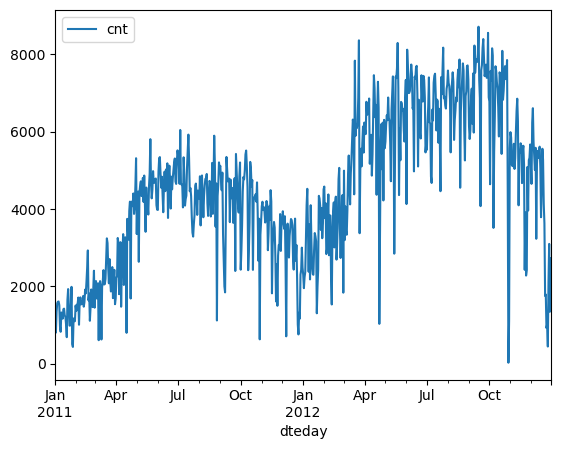

In [33]:
# I plotted the daily rentals to see the trend and the seasonality over time.
# Plot the data present in the dataframe
bike.plot()

as result i see, rentals go up from 2011 to 2012 (trend). They are high in summer and low in winter (seasonality). There are some sudden drops, like at the end of October 2012 (anomalies).

<Axes: xlabel='dteday'>

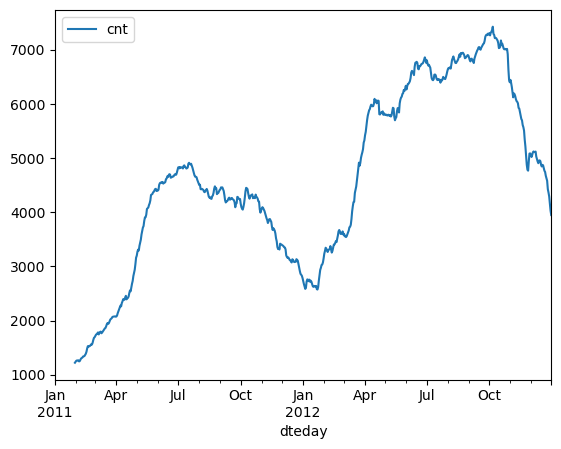

In [34]:
# I plotted the rolling mean to see the trend more clearly.
# I used a window of 30 days (about one month) because my data is daily.
# first test, informally, plot the moving average
bike.rolling(window = 30).mean().plot()

<Axes: xlabel='dteday'>

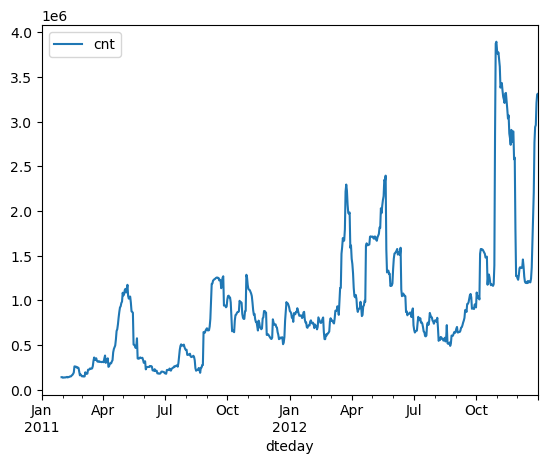

In [35]:
# I plotted the rolling variance to check if the variation changes over time.
bike.rolling(window = 30).var().plot()

i saw , the variance changes over time and is higher in 2012. There is a big peak at the end of October 2012 because of a sudden drop in rentals. This confirms that the series is not stationary.

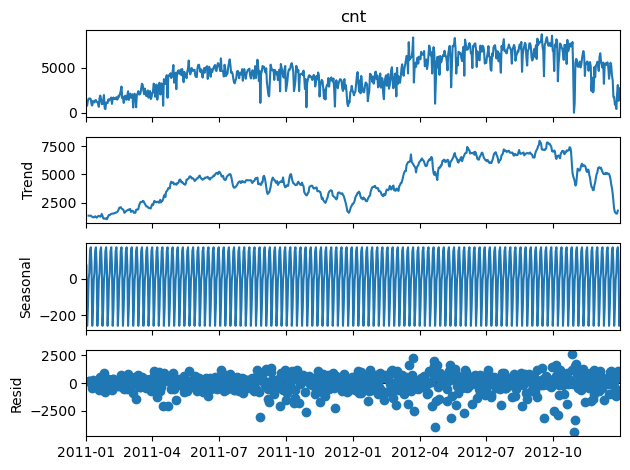

In [36]:
# I used seasonal decomposition to split the series into trend, seasonality and residuals.
# I used period = 7 because the data is daily and rentals repeat every week.
from statsmodels.tsa.seasonal import seasonal_decompose
from matplotlib import pyplot

# decompose the data using seasonal_decompose() function
decomposition = seasonal_decompose(bike['cnt'], model = 'additive', period = 7)

# The additive model is Y[t] = T[t] + S[t] + e[t]

# Plot the function using plot()
decomposition.plot()
pyplot.show()

from this plot i saw, the trend goes up from 2011 to 2012 and drops in winter. The weekly seasonality is small (about ±200 rentals). The residuals show some big drops, which are anomalies caused by bad weather.

In [37]:
%pip show pandas statsmodels xarray

Name: pandas
Version: 3.0.1
Summary: Powerful data structures for data analysis, time series, and statistics
Home-page: https://pandas.pydata.org
Author: 
Author-email: The Pandas Development Team <pandas-dev@python.org>
License: BSD 3-Clause License

 Copyright (c) 2008-2011, AQR Capital Management, LLC, Lambda Foundry, Inc. and PyData Development Team
 All rights reserved.

 Copyright (c) 2011-2026, Open source contributors.

 Redistribution and use in source and binary forms, with or without
 modification, are permitted provided that the following conditions are met:

 * Redistributions of source code must retain the above copyright notice, this
   list of conditions and the following disclaimer.

 * Redistributions in binary form must reproduce the above copyright notice,
   this list of conditions and the following disclaimer in the documentation
   and/or other materials provided with the distribution.

 * Neither the name of the copyright holder nor the names of its
   contribut

In [38]:
import importlib.metadata as md

for pkg in ["statsmodels", "pandas", "xarray"]:
    try:
        print(pkg, md.version(pkg))
    except Exception as e:
        print(pkg, e)

statsmodels 0.15.0
pandas 3.0.1
xarray 2025.10.1


from this plot i saw, the trend goes up from 2011 to 2012 and drops in winter. The weekly seasonality is small (about ±200 rentals). The residuals show some big drops, which are anomalies caused by bad weather.

In [39]:
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '4'  # avoids a Windows warning when running K-Means

In [40]:
import sys
import importlib.metadata as md

print("Python:", sys.version)

for package in ["statsmodels", "pandas", "numpy", "scipy"]:
    try:
        print(f"{package}: {md.version(package)}")
    except md.PackageNotFoundError:
        print(f"{package}: not installed")

Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
statsmodels: 0.15.0
pandas: 3.0.1
numpy: 2.5.4
scipy: 1.18.1


In [41]:
import importlib.metadata as md
import sys

print("Python executable:", sys.executable)

for package in ["statsmodels", "pandas", "scikit-learn", "numpy", "scipy", "pandas-compat"]:
    try:
        print(package, md.version(package))
    except md.PackageNotFoundError:
        print(package, "not installed")

Python executable: C:\Users\user\anaconda3\python.exe
statsmodels 0.15.0
pandas 3.0.1
scikit-learn 1.9.1
numpy 2.5.4
scipy 1.18.1
pandas-compat not installed


In [42]:
%pip install --upgrade --no-cache-dir statsmodels

Note: you may need to restart the kernel to use updated packages.


In [43]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(bike["cnt"])
print("ADF statistic:", result[0])
print("p-value:", result[1])

ADF statistic: -1.8774481444374307
p-value: 0.34274344033921894


In [44]:
# I used the Augmented Dickey-Fuller (ADF) test to check if the series is stationary.
# If the p-value is less than 0.05, the series is stationary.
# If the p-value is more than 0.05, the series is not stationary and needs differencing.
from statsmodels.tsa.stattools import adfuller

# Augmented Dickey-Fuller test
ADF_result = adfuller(bike['cnt'])

# Display the results
print(f'ADF Statistic: {ADF_result[0]}')
print(f'p-value: {ADF_result[1]}')

ADF Statistic: -1.8774481444374307
p-value: 0.34274344033921894


So, the p-value is 0.343, which is more than 0.05. This means the series is not stationary, so I need to apply differencing.

In [45]:
# I applied first-order differencing (today - yesterday) to remove the trend
# and make the series stationary.

# Take the difference
bike_diff = np.diff(bike['cnt'], n = 1)

# Augmented Dickey-Fuller test
ADF_result = adfuller(bike_diff)

# Display the results
print(f'ADF Statistic: {ADF_result[0]}')
print(f'p-value: {ADF_result[1]}')

ADF Statistic: -11.778809074151852
p-value: 1.0467797548021466e-21


i can see, after first-order differencing the p-value is almost 0 (1.05e-21), which is less than 0.05. This means the series is now stationary, so one difference is enough and d = 1.

#### ACF and PACF

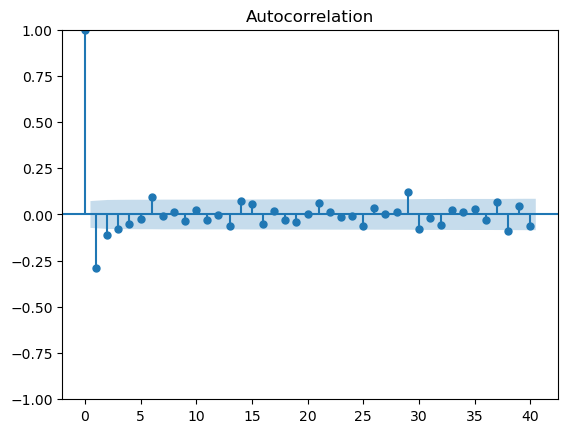

In [46]:
# I plotted the ACF (autocorrelation) of the differenced data to help choose q.
# Bars outside the blue area are significant.
# I also look at lags 7, 14, 21... to check the weekly seasonality.

# Import plot_acf
from statsmodels.graphics.tsaplots import plot_acf

# Plot ACF of the differenced data
plot_acf(bike_diff, lags = 40);

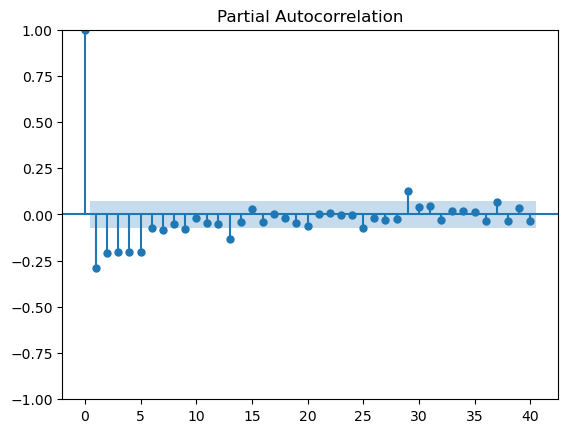

In [47]:
# I plotted the PACF (partial autocorrelation) of the differenced data to help choose p.
# Import plot_pacf
from statsmodels.graphics.tsaplots import plot_pacf

# Plot PACF of the differenced data
plot_pacf(bike_diff, lags = 40);